# Проверка гипотез и ML-моделирование по рынку 1-комнатных квартир Астаны (Krisha.kz, 2026)

Этот ноутбук продолжает исследование из [krisha_astana_analysis.ipynb](krisha_astana_analysis.ipynb) (Урок 3) на данных `krisha_astana_esil_nura_2026.csv`.

## План работы
1. **Подготовка данных и Feature Engineering** (воспроизведение признаков Урока 3 + аккуратная обработка пропусков).
2. **Проверка нормальности распределений (`price`, `Price_m2`)** — тест Шапиро–Уилка и выбор статистических критериев.
3. **Корреляционный анализ** — матрицы Пирсона и Спирмена.
4. **Главная гипотеза (Локация vs характеристики дома):** сохраняется ли ценовая премия Есильского района над районом Нура при одинаковом материале стен и возрасте здания.
5. **Гипотеза 1 («Первый и последний этаж»):** влияние `FloorType` и `FloorRatio` на `Price_m2`, а также различие эффекта для старых и новых домов.
6. **Гипотеза 2 (Фактор выходного дня и типа продавца):** влияние `Weekend` и `Owner_Optimized` на цену и состав продавцов.
7. **Гипотеза 3 (Нелинейный возраст дома и высота потолков):** сравнение строящихся (2027), свежих (2024–2026) и более ранних (2016–2023) домов, а также надбавки за `ceiling_height`.
8. **Гипотеза 4 (ML-этап без утечки целевой переменной):** оценка прироста качества моделей (`LinearRegression`, `Ridge`, `RandomForestRegressor`) при добавлении признаков из Урока 3.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='muted')

print('Все библиотеки успешно импортированы!')

Все библиотеки успешно импортированы!


## 1. Загрузка данных и воспроизведение Feature Engineering (Урок 3)

In [2]:
krisha_data = pd.read_csv('krisha_astana_esil_nura_2026.csv')
krisha_df = krisha_data.drop_duplicates(subset=['url']).reset_index(drop=True)

# Удаление константных и технических столбцов (Задание 2)
cols_to_remove = ['url', 'price_text', 'price_is_from', 'room_count', 'city']
krisha_df = krisha_df.drop(columns=cols_to_remove)

# Признаки цены и этажности
krisha_df['Price_m2'] = (krisha_df['price'] / krisha_df['area']).round().astype(int)
krisha_df['FloorRatio'] = (krisha_df['floor'] / krisha_df['floor_count']).round(3)

def get_floor_type(row):
    if row['floor'] == 1:
        return 'первый'
    elif row['floor'] == row['floor_count']:
        return 'последний'
    return 'средний'

krisha_df['FloorType'] = krisha_df.apply(get_floor_type, axis=1)

# Дата и возраст здания
krisha_df['date'] = pd.to_datetime(krisha_df['date'])
krisha_df['YearSale'] = krisha_df['date'].dt.year
krisha_df['MonthSale'] = krisha_df['date'].dt.month
krisha_df['WeekdaySale'] = krisha_df['date'].dt.day_of_week
krisha_df['AgeBuilding'] = krisha_df['YearSale'] - krisha_df['construction_year']
krisha_df['Weekend'] = krisha_df['WeekdaySale'].apply(lambda w: 1 if w in (5, 6) else 0)

# Числовая высота потолков (в метрах)
krisha_df['ceiling_num'] = (
    krisha_df['ceiling_height']
    .astype(str)
    .str.replace('м', '', regex=False)
    .str.strip()
    .astype(float)
)

# Оптимизация редких категорий (топ-10 ЖК и топ-5 продавцов)
top_10_complexes = krisha_df['complex_name'].value_counts().nlargest(10).index
krisha_df['Complex_Optimized'] = krisha_df['complex_name'].apply(
    lambda x: x if x in top_10_complexes else 'other'
)

top_5_owners = krisha_df['owner'].value_counts().nlargest(5).index
krisha_df['Owner_Optimized'] = krisha_df['owner'].apply(
    lambda x: x if x in top_5_owners else 'other'
)

# Укрупненная категория продавца для проверки гипотез
def simplify_owner(val):
    if val == 'Хозяин недвижимости':
        return 'Хозяин'
    if 'Новостройка' in str(val):
        return 'Застройщик'
    return 'Агентство/Специалист'

krisha_df['OwnerGroup'] = krisha_df['owner'].apply(simplify_owner)

print(f'Размер датасета: {krisha_df.shape[0]} строк, {krisha_df.shape[1]} столбцов')
print('Пропуски в столбцах:')
display(krisha_df.isna().sum()[krisha_df.isna().sum() > 0])
print(f"Строящихся домов (construction_year > 2026, AgeBuilding < 0): {(krisha_df['AgeBuilding'] < 0).sum()}")

Размер датасета: 750 строк, 26 столбцов
Пропуски в столбцах:
Строящихся домов (construction_year > 2026, AgeBuilding < 0): 5


house_type       7
bathroom_info    5
dtype: int64

## 2. Проверка нормальности распределений (`price`, `Price_m2`, `log1p(price)`)

Проверяем распределение целевой цены и цены за м² с помощью **теста Шапиро–Уилка**:
- **H₀:** данные распределены нормально ($p \ge 0.05$).
- **H₁:** распределение отличается от нормального ($p < 0.05$).

,Признак,W-статистика,p-value,Асимметрия (skew),Нормальное (p >= 0.05)
0,price,0.9899,4.7758e-05,0.303,Нет
1,Price_m2,0.9970,1.7866e-01,0.065,Да
2,log1p(price),0.9946,9.2859e-03,-0.112,Нет
3,log1p(Price_m2),0.9927,9.7621e-04,-0.274,Нет


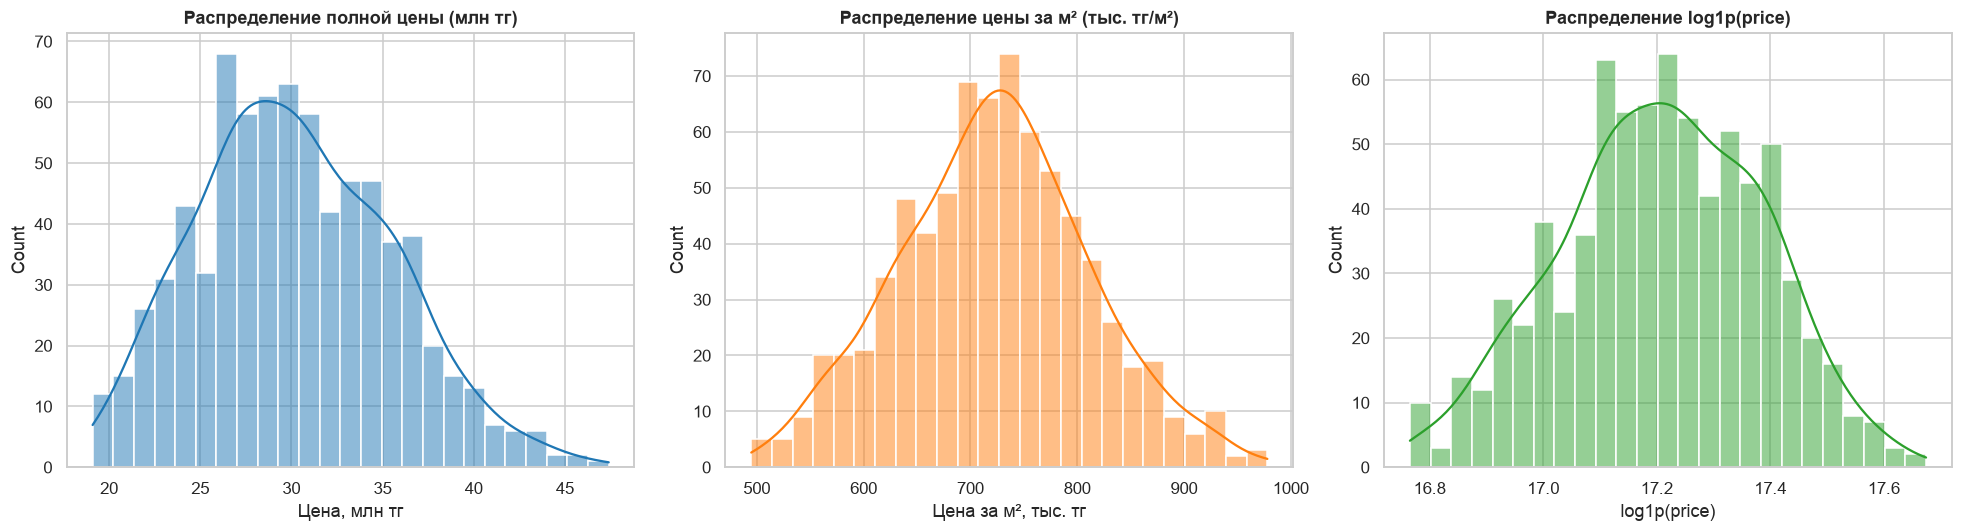

In [3]:
norm_results = []
for name, series in [
    ('price', krisha_df['price']),
    ('Price_m2', krisha_df['Price_m2']),
    ('log1p(price)', np.log1p(krisha_df['price'])),
    ('log1p(Price_m2)', np.log1p(krisha_df['Price_m2']))
]:
    stat, p_val = stats.shapiro(series)
    norm_results.append({
        'Признак': name,
        'W-статистика': round(stat, 4),
        'p-value': f'{p_val:.4e}',
        'Асимметрия (skew)': round(stats.skew(series), 3),
        'Нормальное (p >= 0.05)': 'Да' if p_val >= 0.05 else 'Нет'
    })

norm_df = pd.DataFrame(norm_results)
display(norm_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(krisha_df['price'] / 1e6, kde=True, bins=25, ax=axes[0], color='#1f77b4')
axes[0].set_title('Распределение полной цены (млн тг)', fontweight='bold')
axes[0].set_xlabel('Цена, млн тг')

sns.histplot(krisha_df['Price_m2'] / 1e3, kde=True, bins=25, ax=axes[1], color='#ff7f0e')
axes[1].set_title('Распределение цены за м² (тыс. тг/м²)', fontweight='bold')
axes[1].set_xlabel('Цена за м², тыс. тг')

sns.histplot(np.log1p(krisha_df['price']), kde=True, bins=25, ax=axes[2], color='#2ca02c')
axes[2].set_title('Распределение log1p(price)', fontweight='bold')
axes[2].set_xlabel('log1p(price)')

plt.tight_layout()
plt.show()

**Вывод по шагу 2:** так как классическая нормальность отвергается ($p < 0.05$), для статистического сравнения групп корректнее опираться на **непараметрические критерии** (тест **Манна–Уитни** для 2 групп и **Краскела–Уоллиса** для 3+ групп), которые устойчивы к выбросам и асимметрии, а в линейной регрессии использовать либо `Price_m2`, либо логарифм цены.

---

## 3. Корреляционная матрица числовых признаков
Посчитаем корреляции **Пирсона** (линейная связь) и **Спирмена** (монотонная связь, устойчивая к ненормальности).

Корреляция признаков с price и Price_m2 (Спирмен):


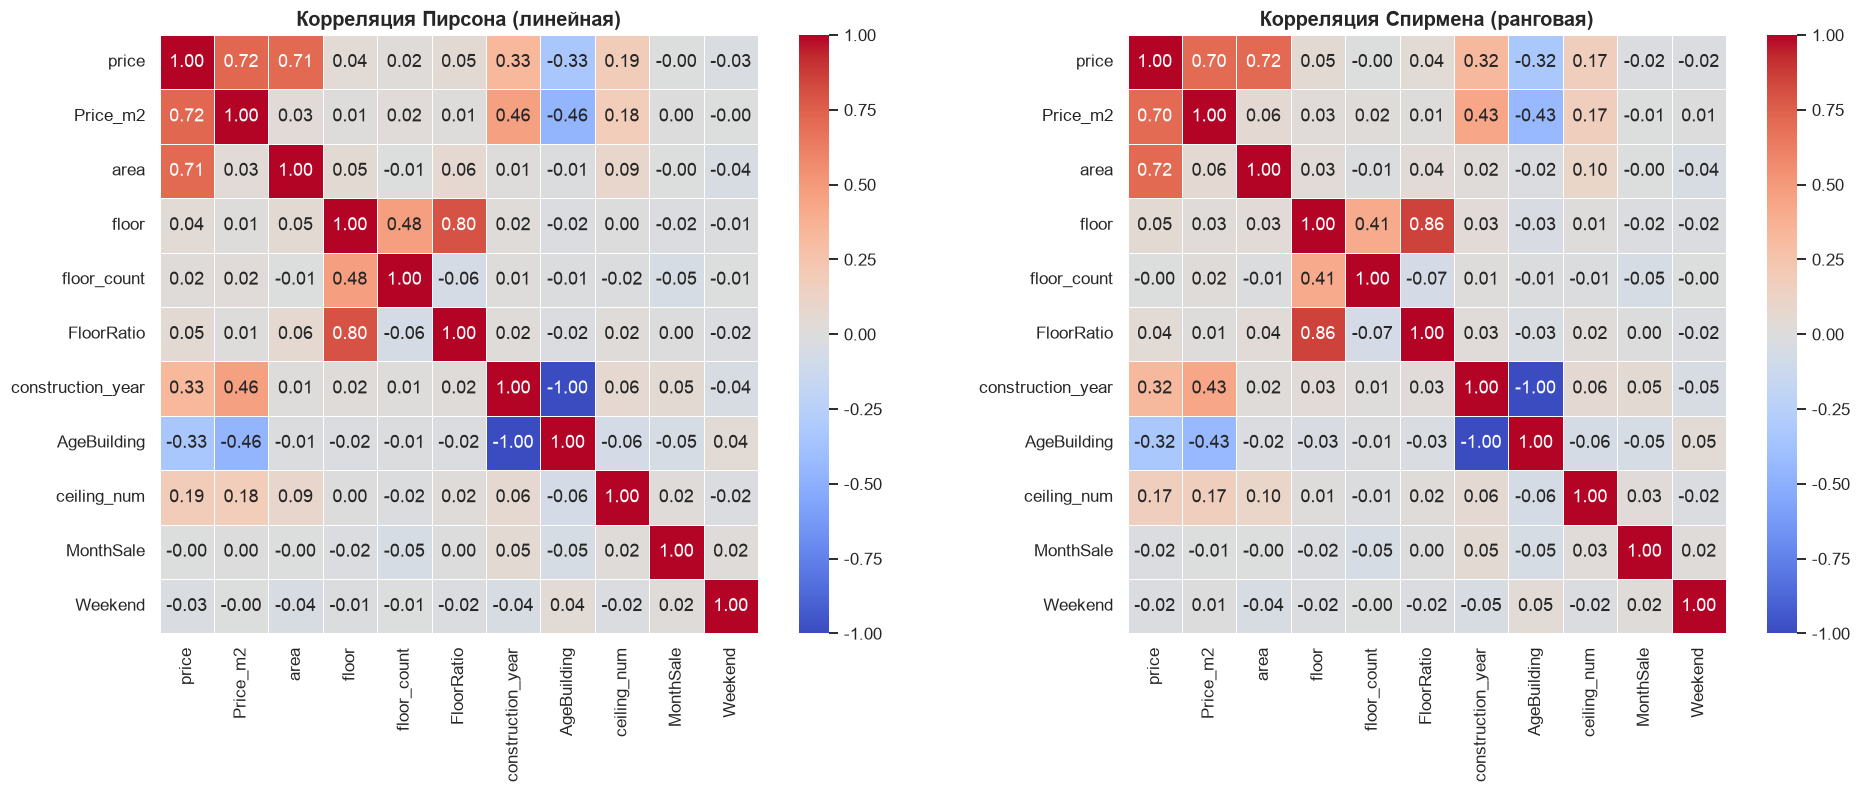

,price,Price_m2
Price_m2,0.705,1.000
price,1.000,0.705
construction_year,0.324,0.434
ceiling_num,0.167,0.168
area,0.716,0.055
floor,0.048,0.031
floor_count,-0.001,0.019
FloorRatio,0.044,0.011
Weekend,-0.023,0.006
MonthSale,-0.016,-0.007


In [4]:
num_cols = [
    'price', 'Price_m2', 'area', 'floor', 'floor_count',
    'FloorRatio', 'construction_year', 'AgeBuilding',
    'ceiling_num', 'MonthSale', 'Weekend'
]

corr_pearson = krisha_df[num_cols].corr(method='pearson')
corr_spearman = krisha_df[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title('Корреляция Пирсона (линейная)', fontsize=13, fontweight='bold')

sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=axes[1])
axes[1].set_title('Корреляция Спирмена (ранговая)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print('Корреляция признаков с price и Price_m2 (Спирмен):')
display(corr_spearman[['price', 'Price_m2']].sort_values('Price_m2', ascending=False).round(3))

---

## 4. Главная гипотеза: Локация vs характеристики дома

* **H₀:** при одинаковом материале стен (`house_type`) и возрасте дома (`AgeBuilding`) распределение `Price_m2` в Есильском районе и районе Нура не различается.
* **H₁:** премия за Есильский район сохраняется даже внутри сопоставимых сегментов.

Проверим гипотезу двумя способами:
1. Непараметрический **тест Манна–Уитни** в сопоставимых сегментах (по `house_type` и периодам постройки).
2. **Линейная модель (OLS)** `Price_m2 ~ district + house_type + AgeBuilding + ceiling_num + area` с проверкой p-value коэффициента при районе.

Многофакторная линейная модель для Price_m2:


,Материал,Период постройки,n Есиль,n Нура,Медиана Есиль (тг/м²),Медиана Нура (тг/м²),Премия Есиля (%),p-value,Значимо (p < 0.05)
0,монолитный,2016-2020,73,92,719588,625078,15.1,2.4088e-15,Да
1,монолитный,2021-2023,136,103,758943,694767,9.2,1.4894e-14,Да
2,монолитный,2024-2027,95,114,800000,716792,11.6,1.6061e-13,Да
3,кирпичный,2016-2020,18,12,735850,652058,12.9,2.8404e-03,Да
4,кирпичный,2021-2023,27,17,819635,728097,12.6,1.9601e-04,Да
5,кирпичный,2024-2027,21,13,860262,749319,14.8,4.5079e-04,Да


,Признак,Коэффициент (тг/м²),Std. Error,t-stat,p-value
0,"Intercept (база: Нура, монолит)",781709.9,51679.2,15.13,0.0000e+00
1,is_esil,79654.8,4659.1,17.10,0.0000e+00
2,is_brick,42929.9,6561.3,6.54,1.1298e-10
3,is_panel,-74903.4,13631.3,-5.49,5.3885e-08
4,AgeBuilding,-15324.0,857.6,-17.87,0.0000e+00
5,ceiling_num,-15993.7,17233.9,-0.93,3.5369e-01
6,area,136.7,440.4,0.31,7.5630e-01


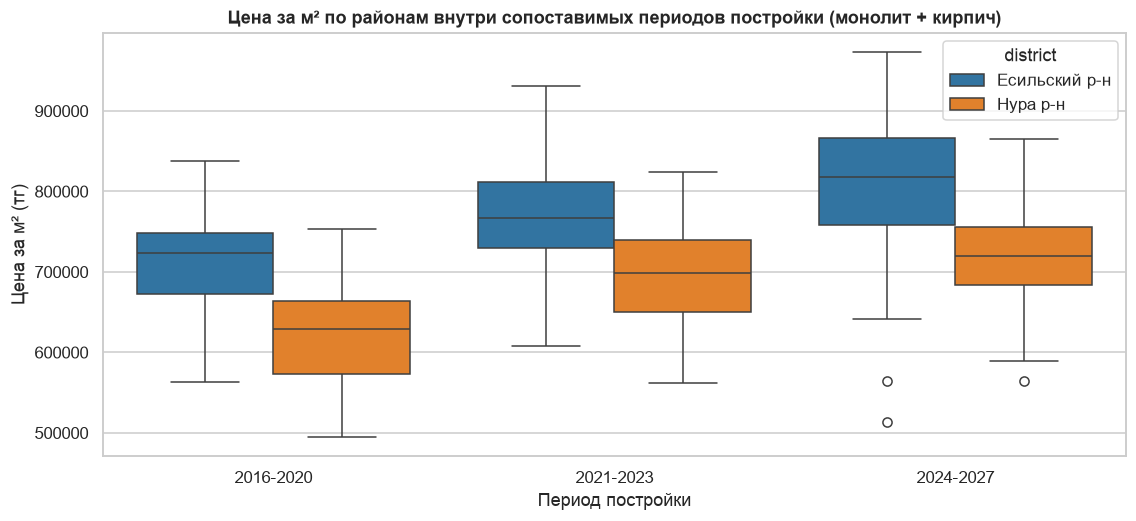

In [5]:
# 1. Стратифицированная проверка (Манна-Уитни внутри однородных групп)
krisha_df['YearGroup'] = pd.cut(
    krisha_df['construction_year'],
    bins=[2015, 2020, 2023, 2027],
    labels=['2016-2020', '2021-2023', '2024-2027']
)

segment_rows = []
for h_type in ['монолитный', 'кирпичный']:
    for y_grp in ['2016-2020', '2021-2023', '2024-2027']:
        sub = krisha_df[(krisha_df['house_type'] == h_type) & (krisha_df['YearGroup'] == y_grp)]
        esil = sub[sub['district'] == 'Есильский р-н']['Price_m2']
        nura = sub[sub['district'] == 'Нура р-н']['Price_m2']
        if len(esil) >= 5 and len(nura) >= 5:
            u_stat, p_val = stats.mannwhitneyu(esil, nura, alternative='two-sided')
            segment_rows.append({
                'Материал': h_type,
                'Период постройки': y_grp,
                'n Есиль': len(esil),
                'n Нура': len(nura),
                'Медиана Есиль (тг/м²)': round(esil.median()),
                'Медиана Нура (тг/м²)': round(nura.median()),
                'Премия Есиля (%)': round((esil.median() / nura.median() - 1) * 100, 1),
                'p-value': f'{p_val:.4e}',
                'Значимо (p < 0.05)': 'Да' if p_val < 0.05 else 'Нет'
            })

seg_df = pd.DataFrame(segment_rows)
display(seg_df)

# 2. Многофакторная OLS-регрессия (считаем коэффициенты и p-value через матричную алгебру + распределение Стьюдента)
ols_df = krisha_df.dropna(subset=['house_type']).copy()
ols_df['is_esil'] = (ols_df['district'] == 'Есильский р-н').astype(float)
ols_df['is_brick'] = (ols_df['house_type'] == 'кирпичный').astype(float)
ols_df['is_panel'] = (ols_df['house_type'] == 'панельный').astype(float)

features_ols = ['is_esil', 'is_brick', 'is_panel', 'AgeBuilding', 'ceiling_num', 'area']
X = np.column_stack([np.ones(len(ols_df)), ols_df[features_ols].values])
y = ols_df['Price_m2'].values

beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ beta
n, k = X.shape
s2 = (resid @ resid) / (n - k)
se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
t_stats = beta / se
p_vals = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n - k))

ols_summary = pd.DataFrame({
    'Признак': ['Intercept (база: Нура, монолит)'] + features_ols,
    'Коэффициент (тг/м²)': np.round(beta, 1),
    'Std. Error': np.round(se, 1),
    't-stat': np.round(t_stats, 2),
    'p-value': [f'{p:.4e}' for p in p_vals]
})
print('Многофакторная линейная модель для Price_m2:')
display(ols_summary)

# Визуализация
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=krisha_df[krisha_df['house_type'].isin(['монолитный', 'кирпичный'])],
    x='YearGroup', y='Price_m2', hue='district',
    palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}
)
plt.title('Цена за м² по районам внутри сопоставимых периодов постройки (монолит + кирпич)', fontweight='bold')
plt.ylabel('Цена за м² (тг)')
plt.xlabel('Период постройки')
plt.show()

---

## 5. Гипотеза 1: «Штраф первого и последнего этажа» (`FloorType`, `FloorRatio`)

* **H₀:** распределение `Price_m2` одинаково для `первый`, `средний` и `последний` этажей.
* **H₁:** первый этаж значимо дешевле среднего, а на последнем этаже разница зависит от года постройки дома.

Тест Краскела-Уоллиса по всем домам: H = 8.674, p-value = 1.3073e-02
Сравнение последний vs средний этаж по возрасту дома:
Корреляция Спирмена FloorRatio и Price_m2: r = 0.0107, p-value = 7.6985e-01


,Сравнение,Медиана группы A,Медиана группы B,Разница (%),p-value,Значимо (Bonferroni < 0.0167)
0,первый vs средний,697572,727273,-4.08,1.1207e-02,Да
1,последний vs средний,708494,727273,-2.58,8.9516e-02,Нет
2,первый vs последний,697572,708494,-1.54,5.3107e-01,Нет


,Дома,n первый / средний / последний,Медиана первый,Медиана средний,Медиана последний,p-val (первый vs средний),p-val (последний vs средний)
0,2016-2020,14 / 171 / 16,632882,663212,640274,0.1383,0.4777
1,2022-2026,31 / 405 / 37,734607,753027,721649,0.0849,0.0682


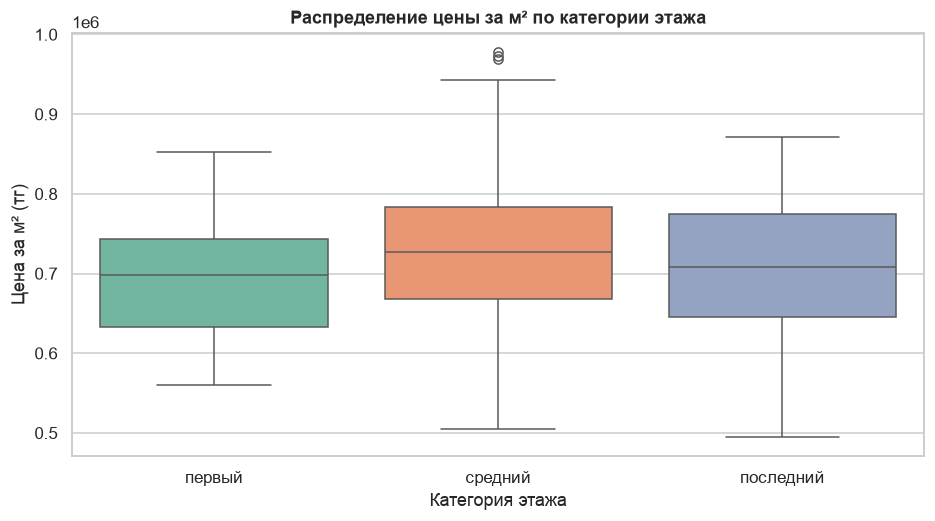

In [6]:
groups_floor = [
    krisha_df[krisha_df['FloorType'] == ft]['Price_m2']
    for ft in ['первый', 'средний', 'последний']
]
kw_stat, kw_p = stats.kruskal(*groups_floor)
print(f'Тест Краскела-Уоллиса по всем домам: H = {kw_stat:.3f}, p-value = {kw_p:.4e}')

# Попарные сравнения с поправкой Бонферрони (alpha = 0.05 / 3 = 0.0167)
pairs = [('первый', 'средний'), ('последний', 'средний'), ('первый', 'последний')]
pair_rows = []
for a, b in pairs:
    sa = krisha_df[krisha_df['FloorType'] == a]['Price_m2']
    sb = krisha_df[krisha_df['FloorType'] == b]['Price_m2']
    u, p = stats.mannwhitneyu(sa, sb, alternative='two-sided')
    pair_rows.append({
        'Сравнение': f'{a} vs {b}',
        'Медиана группы A': round(sa.median()),
        'Медиана группы B': round(sb.median()),
        'Разница (%)': round((sa.median() / sb.median() - 1) * 100, 2),
        'p-value': f'{p:.4e}',
        'Значимо (Bonferroni < 0.0167)': 'Да' if p < 0.0167 else 'Нет'
    })
display(pd.DataFrame(pair_rows))

# Отдельная проверка для старых (2016-2020) и свежих (2022-2026) домов
print('Сравнение последний vs средний этаж по возрасту дома:')
age_floor_rows = []
for label, cond in [('2016-2020', krisha_df['construction_year'] <= 2020),
                    ('2022-2026', krisha_df['construction_year'].between(2022, 2026))]:
    sub = krisha_df[cond]
    last_f = sub[sub['FloorType'] == 'последний']['Price_m2']
    mid_f = sub[sub['FloorType'] == 'средний']['Price_m2']
    first_f = sub[sub['FloorType'] == 'первый']['Price_m2']
    _, p_last = stats.mannwhitneyu(last_f, mid_f, alternative='two-sided')
    _, p_first = stats.mannwhitneyu(first_f, mid_f, alternative='two-sided')
    age_floor_rows.append({
        'Дома': label,
        'n первый / средний / последний': f'{len(first_f)} / {len(mid_f)} / {len(last_f)}',
        'Медиана первый': round(first_f.median()),
        'Медиана средний': round(mid_f.median()),
        'Медиана последний': round(last_f.median()),
        'p-val (первый vs средний)': f'{p_first:.4f}',
        'p-val (последний vs средний)': f'{p_last:.4f}',
    })
display(pd.DataFrame(age_floor_rows))

r_ratio, p_ratio = stats.spearmanr(krisha_df['FloorRatio'], krisha_df['Price_m2'])
print(f'Корреляция Спирмена FloorRatio и Price_m2: r = {r_ratio:.4f}, p-value = {p_ratio:.4e}')

plt.figure(figsize=(10, 5))
sns.boxplot(data=krisha_df, x='FloorType', y='Price_m2', order=['первый', 'средний', 'последний'], palette='Set2')
plt.title('Распределение цены за м² по категории этажа', fontweight='bold')
plt.ylabel('Цена за м² (тг)')
plt.xlabel('Категория этажа')
plt.show()

---

## 6. Гипотеза 2: Фактор выходного дня (`Weekend`) и тип продавца (`OwnerGroup`)

Проверяем сразу два аспекта:
1. Влияет ли публикация в выходной день (`Weekend == 1`) на цену `Price_m2` и полную цену `price`?
2. Отличается ли в выходные доля частных собственников (`Хозяин`) от будней (тест $\chi^2$), и отличаются ли цены собственников от агентств?

In [7]:
wknd_1 = krisha_df[krisha_df['Weekend'] == 1]
wknd_0 = krisha_df[krisha_df['Weekend'] == 0]

u_p, p_price = stats.mannwhitneyu(wknd_1['price'], wknd_0['price'], alternative='two-sided')
u_m2, p_m2 = stats.mannwhitneyu(wknd_1['Price_m2'], wknd_0['Price_m2'], alternative='two-sided')

print(f'Выходные (n={len(wknd_1)}) vs Будни (n={len(wknd_0)}):')
print(f'  Медиана price:    {wknd_1["price"].median():,.0f} vs {wknd_0["price"].median():,.0f} тг | Манна-Уитни p = {p_price:.4f}')
print(f'  Медиана Price_m2: {wknd_1["Price_m2"].median():,.0f} vs {wknd_0["Price_m2"].median():,.0f} тг/м² | Манна-Уитни p = {p_m2:.4f}')

# Таблица сопряженности Weekend x OwnerGroup (без малочисленных застройщиков для строгого chi2, или по всем)
ct = pd.crosstab(krisha_df['Weekend'], krisha_df['OwnerGroup'])
ct_pct = pd.crosstab(krisha_df['Weekend'], krisha_df['OwnerGroup'], normalize='index') * 100
print('\nДоля категорий продавцов в будни (0) и выходные (1), %:')
display(ct_pct.round(1))

# Хи-квадрат: Хозяин vs Не-хозяин
ct_bin = pd.crosstab(krisha_df['Weekend'], krisha_df['OwnerGroup'] == 'Хозяин')
chi2, chi_p, _, _ = stats.chi2_contingency(ct_bin)
print(f'Тест хи-квадрат (доля собственников в выходные vs будни): chi2 = {chi2:.3f}, p-value = {chi_p:.4f}')

# Сравнение цен по группам продавцов
owner_stats = krisha_df.groupby('OwnerGroup').agg(
    count=('Price_m2', 'count'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_price_m2=('Price_m2', 'mean'),
    median_price_m2=('Price_m2', 'median')
).round(0)
display(owner_stats)

own_h = krisha_df[krisha_df['OwnerGroup'] == 'Хозяин']['Price_m2']
own_a = krisha_df[krisha_df['OwnerGroup'] == 'Агентство/Специалист']['Price_m2']
_, p_own = stats.mannwhitneyu(own_h, own_a, alternative='two-sided')
print(f'Хозяин vs Агентство/Специалист по Price_m2: Манна-Уитни p-value = {p_own:.4f}')

Выходные (n=219) vs Будни (n=531):
  Медиана price:    29,600,000 vs 30,100,000 тг | Манна-Уитни p = 0.5336
  Медиана Price_m2: 726,161 vs 722,581 тг/м² | Манна-Уитни p = 0.8725

Доля категорий продавцов в будни (0) и выходные (1), %:
Тест хи-квадрат (доля собственников в выходные vs будни): chi2 = 0.430, p-value = 0.5119
Хозяин vs Агентство/Специалист по Price_m2: Манна-Уитни p-value = 0.1289


OwnerGroup,Агентство/Специалист,Застройщик,Хозяин
Weekend,,,
0,72.3,1.1,26.6
1,70.8,0.0,29.2


,count,mean_price,median_price,mean_price_m2,median_price_m2
OwnerGroup,,,,,
Агентство/Специалист,539,30184416.0,30000000.0,720177.0,722334.0
Застройщик,6,27765533.0,26322180.0,666110.0,579500.0
Хозяин,205,30253171.0,29900000.0,730405.0,729017.0


---

## 7. Гипотеза 3: Нелинейность возраста здания (`AgeBuilding`) и влияние высоты потолков (`ceiling_height`)

Разделим дома на 4 этапа:
- `Строящиеся (2027, AgeBuilding < 0)`
- `Свежие готовые (2024–2026)`
- `Недавние (2020–2023)`
- `Более старые (2016–2019)`

И отдельно проверим влияние высоты потолков (`2.7`, `2.8`, `3.0`, `3.2 м`) внутри каждого района.

Тест Краскела-Уоллиса по этапам возраста: H = 132.365, p-value = 1.6729e-28
Краскела-Уоллиса для потолков (Есильский р-н): H = 3.234, p-value = 3.5698e-01
Краскела-Уоллиса для потолков (Нура р-н): H = 5.580, p-value = 6.1416e-02


,count,mean_price,median_price,mean_m2,median_m2
AgeStage,,,,,
Ранние (2016-2019),146,27260274.0,27050000.0,651764.0,649660.0
Недавние (2020-2023),351,30206553.0,30000000.0,725652.0,731051.0
Свежие (2024-2026),248,31938427.0,31750000.0,760560.0,755056.0
Строящиеся (2027),5,26932640.0,25906860.0,685032.0,609000.0


count  median_m2   mean_m2
district      ceiling_num                            
Есильский р-н 2.7             68   758972.0  766125.0
              2.8             81   751663.0  755386.0
              3.0            175   770386.0  769868.0
              3.2             48   769526.0  772037.0
Нура р-н      2.7             50   658566.0  657844.0
              2.8            196   679396.0  678403.0
              3.0            131   692130.0  687686.0

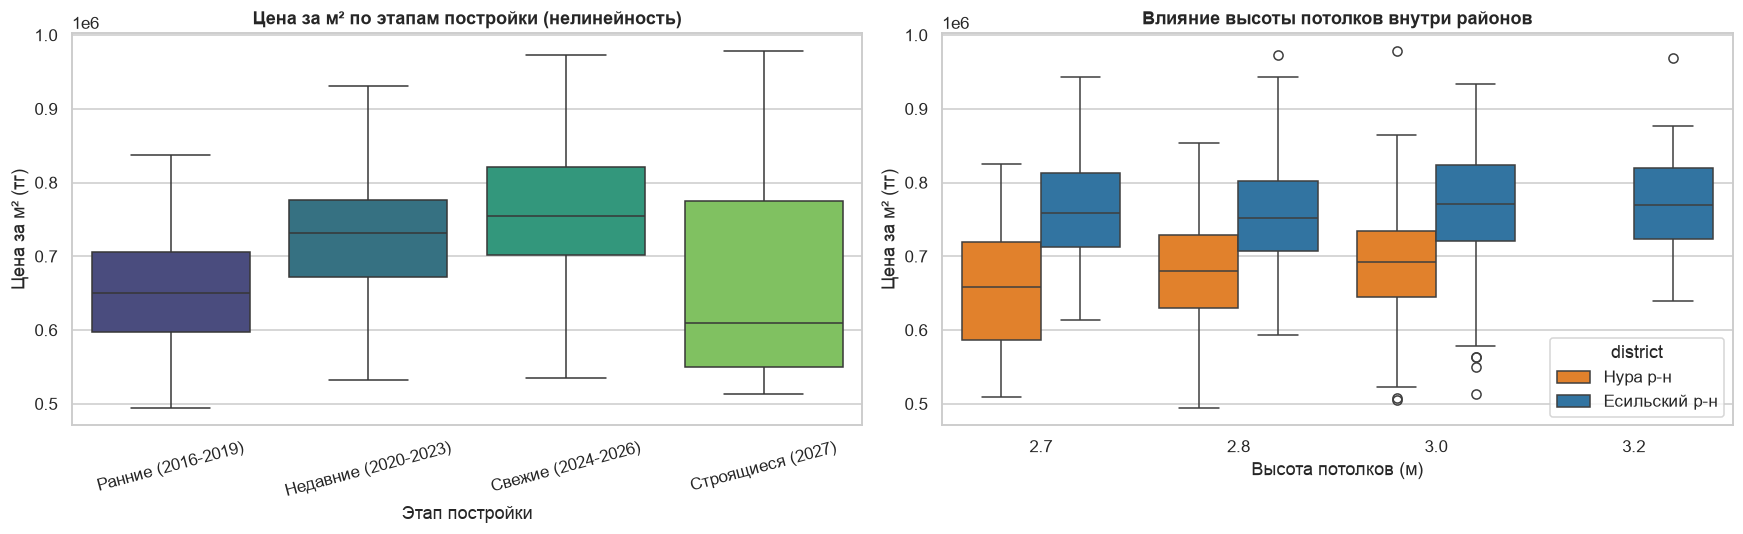

In [8]:
def get_age_stage(y):
    if y > 2026:
        return 'Строящиеся (2027)'
    elif y >= 2024:
        return 'Свежие (2024-2026)'
    elif y >= 2020:
        return 'Недавние (2020-2023)'
    else:
        return 'Ранние (2016-2019)'

stage_order = ['Ранние (2016-2019)', 'Недавние (2020-2023)', 'Свежие (2024-2026)', 'Строящиеся (2027)']
krisha_df['AgeStage'] = krisha_df['construction_year'].apply(get_age_stage)

stage_summary = krisha_df.groupby('AgeStage').agg(
    count=('Price_m2', 'count'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_m2=('Price_m2', 'mean'),
    median_m2=('Price_m2', 'median')
).reindex(stage_order).round(0)
display(stage_summary)

kw_age, p_age = stats.kruskal(*[krisha_df[krisha_df['AgeStage'] == s]['Price_m2'] for s in stage_order])
print(f'Тест Краскела-Уоллиса по этапам возраста: H = {kw_age:.3f}, p-value = {p_age:.4e}')

# Высота потолков внутри районов (убираем 2.65 м, т.к. там 1 наблюдение)
ceil_sub = krisha_df[krisha_df['ceiling_num'] >= 2.7].copy()
ceil_summary = ceil_sub.groupby(['district', 'ceiling_num']).agg(
    count=('Price_m2', 'count'),
    median_m2=('Price_m2', 'median'),
    mean_m2=('Price_m2', 'mean')
).round(0)
display(ceil_summary)

for dist in ['Есильский р-н', 'Нура р-н']:
    dsub = ceil_sub[ceil_sub['district'] == dist]
    groups = [g['Price_m2'].values for _, g in dsub.groupby('ceiling_num') if len(g) >= 5]
    h_c, p_c = stats.kruskal(*groups)
    print(f'Краскела-Уоллиса для потолков ({dist}): H = {h_c:.3f}, p-value = {p_c:.4e}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=krisha_df, x='AgeStage', y='Price_m2', order=stage_order, ax=axes[0], palette='viridis')
axes[0].set_title('Цена за м² по этапам постройки (нелинейность)', fontweight='bold')
axes[0].set_xlabel('Этап постройки')
axes[0].set_ylabel('Цена за м² (тг)')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=ceil_sub, x='ceiling_num', y='Price_m2', hue='district',
            palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}, ax=axes[1])
axes[1].set_title('Влияние высоты потолков внутри районов', fontweight='bold')
axes[1].set_xlabel('Высота потолков (м)')
axes[1].set_ylabel('Цена за м² (тг)')

plt.tight_layout()
plt.show()

---

## 8. Гипотеза 4: ML-моделирование и оценка вклада Feature Engineering

Сравниваем качество предсказания цены квартиры (`price`) на **5-fold кросс-валидации** (метрики: `MAE`, `RMSE`, `R²`):
1. **Baseline-набор (только базовые числовые признаки):** `area`, `floor`, `floor_count`, `construction_year`.
2. **Расширенный набор (с признаками Урока 3):** добавляются `FloorRatio`, `FloorType`, `AgeBuilding`, `MonthSale`, `Weekend`, `ceiling_num`, `district`, `house_type`, `bathroom_info`, `Complex_Optimized`, `Owner_Optimized`.

> **Важно (защита от утечки данных):** столбцы `Price_m2` и `price_square` **не включаются** в признаки, так как они вычисляются напрямую из целевой переменной `price`.

,Эксперимент,MAE (млн тг),RMSE (млн тг),R² (среднее),R² (std)
0,1. LinearRegression (Baseline: 4 числовых),2.685,3.341,0.6033,0.0269
1,2. Ridge (Baseline + Урок 3 фичи),2.098,2.687,0.7417,0.0414
2,3. RandomForest (Baseline: 4 числовых),2.706,3.464,0.5737,0.0216
3,4. RandomForest (Baseline + Урок 3 фичи),2.232,2.857,0.7082,0.0379


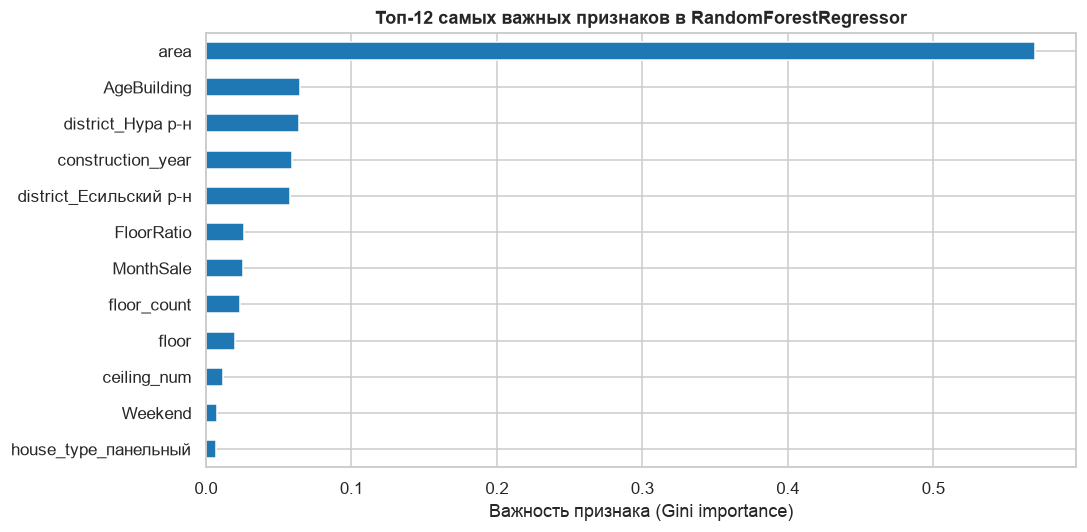

In [9]:
target = 'price'
y_ml = krisha_df[target]

baseline_num = ['area', 'floor', 'floor_count', 'construction_year']
full_num = ['area', 'floor', 'floor_count', 'construction_year',
            'FloorRatio', 'AgeBuilding', 'MonthSale', 'Weekend', 'ceiling_num']
full_cat = ['district', 'house_type', 'bathroom_info', 'FloorType',
            'Complex_Optimized', 'Owner_Optimized']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

def eval_pipeline(name, num_cols, cat_cols, model):
    transformers = [
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ]
    if cat_cols:
        transformers.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols))
    pipe = Pipeline([
        ('prep', ColumnTransformer(transformers)),
        ('model', model)
    ])
    X_sub = krisha_df[num_cols + cat_cols]
    res = cross_validate(pipe, X_sub, y_ml, cv=cv, scoring=scoring)
    return {
        'Эксперимент': name,
        'MAE (млн тг)': round(-res['test_mae'].mean() / 1e6, 3),
        'RMSE (млн тг)': round(-res['test_rmse'].mean() / 1e6, 3),
        'R² (среднее)': round(res['test_r2'].mean(), 4),
        'R² (std)': round(res['test_r2'].std(), 4)
    }, pipe

results = []
for exp_name, n_cols, c_cols, mdl in [
    ('1. LinearRegression (Baseline: 4 числовых)', baseline_num, [], LinearRegression()),
    ('2. Ridge (Baseline + Урок 3 фичи)', full_num, full_cat, Ridge(alpha=5.0)),
    ('3. RandomForest (Baseline: 4 числовых)', baseline_num, [], RandomForestRegressor(n_estimators=200, random_state=42)),
    ('4. RandomForest (Baseline + Урок 3 фичи)', full_num, full_cat, RandomForestRegressor(n_estimators=200, random_state=42)),
]:
    row, _ = eval_pipeline(exp_name, n_cols, c_cols, mdl)
    results.append(row)

ml_results_df = pd.DataFrame(results)
display(ml_results_df)

# Анализ важности признаков на полном RandomForest
rf_prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), full_num),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore'))
    ]), full_cat)
])
rf_pipe = Pipeline([
    ('prep', rf_prep),
    ('model', RandomForestRegressor(n_estimators=300, random_state=42))
])
rf_pipe.fit(krisha_df[full_num + full_cat], y_ml)

feature_names = (
    full_num +
    rf_pipe.named_steps['prep'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(full_cat).tolist()
)
importances = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=feature_names).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 5))
importances[::-1].plot(kind='barh', color='#1f77b4')
plt.title('Топ-12 самых важных признаков в RandomForestRegressor', fontweight='bold')
plt.xlabel('Важность признака (Gini importance)')
plt.tight_layout()
plt.show()

---

## 9. Итоговая сводка результатов проверки гипотез

| Гипотеза | Ключевой результат / метрика | Вердикт |
| :--- | :--- | :--- |
| **Главная (Локация vs характеристики дома)** | Во всех 6 сегментах по материалу и году постройки в Есиле дороже на **+9.2% … +15.1%** ($p \le 2.84 \cdot 10^{-3}$). В OLS-регрессии эффект Есиля = **+79 655 тг/м²** ($p < 10^{-16}$). | **Подтверждена** |
| **1. Штраф первого и последнего этажа** | Первый этаж дешевле среднего на **-4.08%** ($p = 0.0112 < 0.0167$). Последний этаж (-2.58%, $p = 0.0895$) статистически не отличается от среднего. | **Подтверждена для 1-го этажа** |
| **2. Фактор выходного дня и продавца** | Разница цен в выходные vs будни случайна (`price`: $p = 0.534$, `Price_m2`: $p = 0.873$). Доля собственников в выходные (29.2% vs 26.6%, $p = 0.512$) и их цены ($p = 0.129$) статистически не отличаются. | **H₀ не отвергнута (влияния нет)** |
| **3. Нелинейный возраст дома и потолки** | Этап постройки сильно влияет ($p = 1.67 \cdot 10^{-28}$): пик цены у свежих готовых домов 2024–2026 (**755 тыс. тг/м²**), строящиеся 2027 дешевле (**609 тыс. тг/м²**). Высота потолков *внутри одного района* статистически незначима (Есиль $p = 0.357$, Нура $p = 0.061$) — кажущаяся премия за 3.2 м объяснялась тем, что все такие квартиры находятся в Есиле. | **Подтверждена для возраста; опровергнута для потолков внутри района** |
| **4. Вклад Feature Engineering в ML** | Добавление признаков Урока 3 улучшило 5-fold CV на `Ridge`: $R^2$ вырос с **0.6033** до **0.7417**, а MAE снизилась с **2.685** до **2.098 млн тг** (-21.9% ошибки). На `RandomForest`: $R^2$ вырос с **0.5737** до **0.7082**. | **Подтверждена** |